# Solving Inverse Problem using Connectome Spectrum Electromagnetic Tomography (CSET)

In this section we will solve the inverse problem using our new method CSET. This requires the eeg measurements, the forward solution and the connectome spectrum transform (prior). <br>
The method solves the following problem: $$\vec{x}^* = \text{argmin}_{\vec{x}} \lVert A\vec{x}-b \rVert_2^2 + \lambda_1 \lVert W\vec{x} \rVert_2^2 + \lambda_2 \lVert F\vec{x}\rVert_1$$
where
- $\vec{x}^* \in \mathbb{R}^n$ is the reconstructed brain activity.
- $\vec{x} \in \mathbb{R}^n$ is the brain activity.
- $\vec{b} \in \mathbb{R}^m$ are the eeg measurements.
- $A \in \mathbb{R}^{m\times n}$ is the forward matrix.
- $W \in \mathbb{R}^{n \times n}$ are the source covariances. Usually weighted to give more freedom to deep sources
- $F \in \mathbb{R}^{n \times n}$ is the connectome spectrum transform.
- $\lambda \in \mathbb{R}$ is the regularizer parameter.

Regularizing with $\lVert F\vec{x} \rVert_1$ imposes the connectome spectrum of $\vec{x}$ to be sparse and $\lambda$ 

# Batch Wise Run
Run the code for all subjects of a given dataset.

## 📦 Imports

In [1]:
import mindmap as mm 
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- Configuration file (`config`)
- `subjects`: list of subjects to process
- `samples`: list of samples to process


🎚️ **<font color=pink>Parameters</font>**
- Regularizer parameter (`lam`)
- Depth Weighting scale (`dw`)
- Window size (`win_size`): time window around EEG peak in [s]

In [7]:
# config
config   = mm.io.read_config("../configurations/spike.yml")
subjects = config["SUBS"]
samples  = config["SAMP"]
mm_dir   = Path(config["MM_DIR"])

# options
overwrite = True 

# parameters 
win_size = 0.1
alpha    = 0.9
dw       = 1/2

# file naming
fstc = lambda sub, samp: mm_dir/sub/"inv"/f"{sub}_{samp}_eNET-{alpha}"

## ♾️ Loop

In [8]:
for sub in subjects:
    for samp in samples: 

        # check file existence 
        stc_fname = fstc(sub, samp)
        exists = mm.utils.files_exists(stc_fname, mkdir=True)
        if exists and not overwrite:
            print(f"File to generate already exists for subject '{sub}' and sample '{samp}'")
            continue 

        try:
            data = mm.io.read_dataset(sub, "eeg_inv", "fwd", "cst", sample=samp)
            stc  = mm.enet(data["eeg_inv"], data["fwd"], data["cst"], alpha, win_size, scale=1e10, super=True)
        except Exception as e:
            print(f"\033[91mFailed to compute inverse solution for subject '{sub}', sample '{samp}' due to {e}\033[0m")
            continue

        # save
        stc.save(stc_fname, overwrite=True, verbose="warning")
        print(f"\033[92mSuccessfully computed sLORETA inverse solution for subject '{sub}', sample '{samp}'\033[0m")

Failed to compute inverse solution for subject 'sub-pat01', sample 'spike' due to File does not exist: "/media/nino/DATA/SPIKE/derivatives/mindmap/sub-pat01/fwd/sub-pat01_fwd.fif"
DATA SUMMARY
Dataset: spike
Subject: sub-pat02
Retrieved objects:
- cst
- fwd
- eeg_inv
Missing objects:
Successfully computed sLORETA inverse solution for subject 'sub-pat02', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat03
Retrieved objects:
- cst
- fwd
- eeg_inv
Missing objects:
Successfully computed sLORETA inverse solution for subject 'sub-pat03', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat04
Retrieved objects:
- cst
- fwd
- eeg_inv
Missing objects:
Successfully computed sLORETA inverse solution for subject 'sub-pat04', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat05
Retrieved objects:
- cst
- fwd
- eeg_inv
Missing objects:
Successfully computed sLORETA inverse solution for subject 'sub-pat05', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat06
Retri

# Step Wise Run

Run the code step by step for a single subject.

## 📦 Imports

In [1]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

import pyxu.abc as pxa
import pyxu.operator as pxo
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

## 🧠 Data

In [2]:
# configuration
config = mm.io.read_config("../configurations/spike.yml")
sub    = config["SUBS"][16]
sample = config["SAMP"][0]

# data
data = mm.io.read_dataset(sub, "fwd", "cst", "eeg_inv", "gt", "resec", sample=sample)

# features
fwd = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
fwd = fwd["sol"]["data"].astype("float64")                                              # forward matrix

sfreq = data["eeg_inv"].info["sfreq"]

_, ht = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)

t_half = ht/sfreq 
t_peak = pt/sfreq

print(f"50% rising phase time: {t_half:03}")
print(f"Peak time: {t_peak:03}")

DATA SUMMARY
Dataset: spike
Subject: sub-pat17
Retrieved objects:
- resec
- fwd
- eeg_inv
- cst
Missing objects:
- gt
50% rising phase time: 0.464
Peak time: 0.48


#### 🌟 Visualize ground truth

In [3]:
if "gt" in data.keys():
    mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=sfreq)

else:
    plotter = mm.viz.plot_resection(data["fwd"]["src"], data["resec"])
    plotter.add_legend(face="circle")
    plotter.show()

Widget(value='<iframe src="http://localhost:38431/index.html?ui=P_0x76363ab27dd0_0&reconnect=auto" class="pyvi…

In [4]:
if "gt" in data.keys():
    mm.viz.plot_spectrum(data["cst"]@data["gt"].data[:,ht]).show()

#### 🌟 Visualize EEG time series

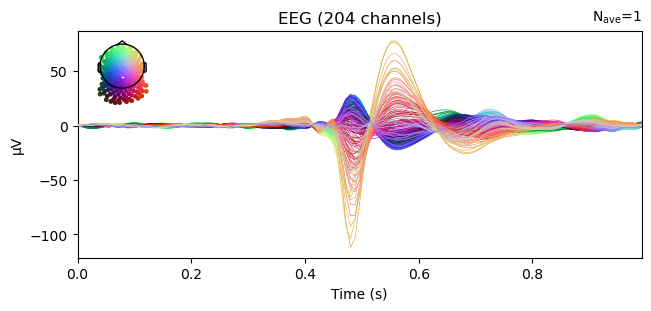

In [5]:
_ = data["eeg_inv"].plot()

#### 🌟 Visualize EEG topographic maps

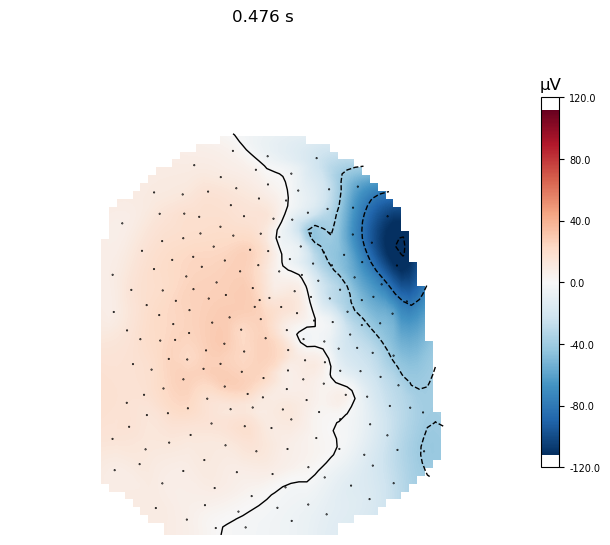

In [6]:
times = [0.476]
_ = data["eeg_inv"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

## Select a Time point

🛠️ <font color=violet>**Select a time window to reconstruct**</font>: One time sample takes around 1 second to reconstruct.
- Window size (`win_size`): time window around EEG peak in [s]

Number of samples: 12


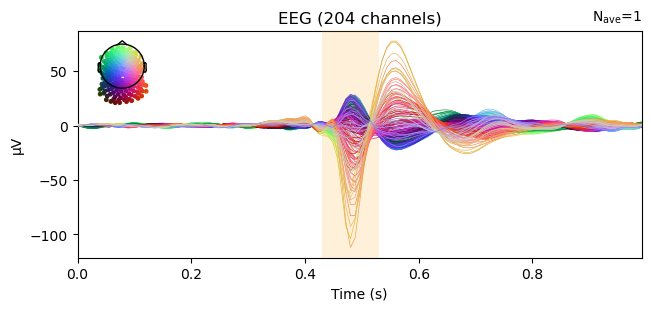

In [7]:
win_size = 0.1      # window size in [s], if None take the 50% rising phase and peak phase only

if win_size is not None:
    dt = int(win_size * sfreq /2)
    Y_  = data["eeg_inv"].data[:, pt-dt:pt+dt]

    t_start  = t_peak-(win_size/2)
    t_end    = t_peak+(win_size/2)
    idx_half = int((t_half-t_start)*sfreq)
    idx_peak = int((t_peak-t_start)*sfreq)

    highlight = [t_start, t_end]

else:
    Y_ = data["eeg_inv"].data[:, [ht,pt]]

    idx_half = 0
    idx_peak = 1

    highlight = [t_half-1e-3, t_half+1e-3], [t_peak-1e-3, t_peak+1e-3]

print(f"Number of samples: {Y_.shape[1]}")
_ = data["eeg_inv"].plot(highlight=highlight)

## Solve The Inverse Problem with CSET

🛠️ <font color=violet>**Select CSET parameters**</font> 
- $\lambda$ (`lam`): regularizer parameter (influences the connectome spectrum sparsity)

In [8]:
alpha = 0.5       # L1/L2 regularizer
dw = 1/2             # depth weighting
cut_freq = None    # cst cut off frequency

⚙️ <font color=green>**Solve inverse problem**</font>: Using the `pyxu` package we can write down any optimization problem and then solve them.

In [9]:
# frequency cutoff
if cut_freq is not None:
    cst = data["cst"][:cut_freq,:]
else:
    cst = data["cst"]

# regularizers
lambda1 = 1 - alpha
lambda2 = alpha
gamma   = lambda1 / (1+lambda2)**(1/2)

# standardize
Ynorms = np.linalg.norm(Y_, axis=0)
Y      = Y_/Ynorms[None,:] + 0.00001

L      = fwd - np.mean(fwd, axis=0)
Lnorms = np.linalg.norm(L, axis=0)**dw
L      = L / Lnorms[None,:] 

# component-wise transformation
L = L @ cst.T

# define artificial data set
L = (1 + lambda2)**(-1/2) * np.vstack([L, lambda2**(1/2)*np.eye(L.shape[1])])
Y = np.vstack([Y, np.zeros((L.shape[1], Y.shape[1]))])

# pyxu components
L     = pxa.LinOp.from_array(L)
prior = gamma*pxo.L1Norm(dim_shape=cst.shape[0])
recon = np.zeros((cst.shape[1], Y.shape[1]))
sc    = pxst.MaxIter(1000)

# ---- optimization ----
for t in range(Y.shape[1]):
    y     = Y[:,t]
    s_hat = np.random.random(L.dim_shape[0])*10**(-9)

    likelihood = pxo.SquaredL2Norm(dim_shape=L.codim_shape).argshift(-y)*L
    likelihood.diff_lipschitz = likelihood.estimate_diff_lipschitz()

    solver = PGD(f=likelihood, g=prior, show_progress=False)

    solver.fit(x0=s_hat, stop_crit=sc)

    s_hat      = solver.solution().squeeze()
    s_hat      = (1+lambda2)**(1/2) * s_hat      # enet correction
    recon[:,t] = (cst.T @ s_hat) * Ynorms[t]

#### <font color=yellow>🌟</font> Visualize reconstruction

In [22]:
viz = np.abs(recon) / (np.max(np.abs(recon), axis=0)+1e-15)
mm.viz.plot_brain_time_series(data["fwd"]["src"], viz, t_start=t_start, sfreq=sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:46237/index.html?ui=P_0x727549353ad0_9&reconnect=auto" class="pyvi…

In [23]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(recon[:,idx_peak]), cmap="reds", show_max=True).show()

Widget(value='<iframe src="http://localhost:46237/index.html?ui=P_0x727549351b80_11&reconnect=auto" class="pyv…

In [21]:
mm.viz.plot_spectrum(data["cst"]@recon[:,idx_peak])

#### 💾 Save result

In [ ]:
fname  = f"{sub}_enet-{alpha}"
folder = Path(config["MM_DIR"])/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving source time course of {sub}, {sample}")
vertices = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]
stc = mne.SourceEstimate(recon, vertices, tmin=t_start, tstep=1/sfreq, subject=sub)
stc.save(folder/fname, overwrite=True, verbose="warning")

Saving source time course of sub-pat18, 


# BLABLA

Number of samples: 24


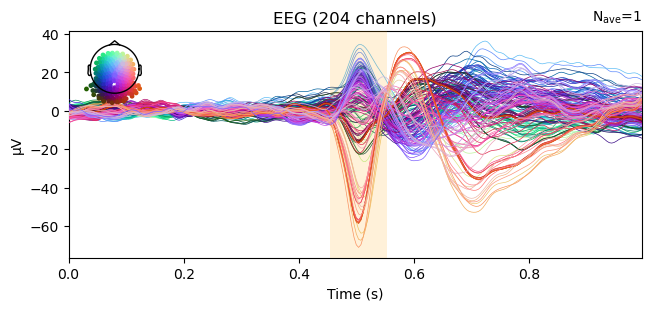

In [11]:
win_size = 0.1      # window size in [s], if None take the 50% rising phase and peak phase only

if win_size is not None:
    dt = int(win_size * sfreq /2)
    Y_  = data["eeg_inv"].data[:, pt-dt:pt+dt]

    t_start  = t_peak-(win_size/2)
    t_end    = t_peak+(win_size/2)
    idx_half = int((t_half-t_start)*sfreq)
    idx_peak = int((t_peak-t_start)*sfreq)

    highlight = [t_start, t_end]

else:
    Y_ = data["eeg_inv"].data[:, [ht,pt]]

    idx_half = 0
    idx_peak = 1

    highlight = [t_half-1e-3, t_half+1e-3], [t_peak-1e-3, t_peak+1e-3]

print(f"Number of samples: {Y_.shape[1]}")
_ = data["eeg_inv"].plot(highlight=highlight)

In [27]:
alpha = 0.9       # L1/L2 regularizer
dw = 1/2             # depth weighting
cut_freq = None    # cst cut off frequency
scale = 1e10       # pyxu does not optimize for small scale so this scales data to big numbers (for optimization) and then descales (for values)

In [28]:
# frequency cutoff
if cut_freq is not None:
    cst = data["cst"][:cut_freq,:]
else:
    cst = data["cst"]

# regularizers
lambda1 = 1 - alpha
lambda2 = alpha
gamma   = lambda1 / (1+lambda2)**(1/2)

# standardize
Ynorms = np.linalg.norm(Y_, axis=0)
Y      = Y_/Ynorms[None,:]
L      = fwd

# depth prior
W = np.diag(np.linalg.norm(L, axis=0)**dw)

# define artificial data set
L = (1 + lambda2)**(-1/2) * np.vstack([L, lambda2**(1/2)*W])
Y = np.vstack([Y, np.zeros((L.shape[1], Y.shape[1]))])

# component-wise transformation
L = L @ cst.T

# pyxu components
L     = pxa.LinOp.from_array(L)
prior = gamma*pxo.L1Norm(dim_shape=cst.shape[0])
recon = np.zeros((cst.shape[1], Y.shape[1]))
sc    = pxst.MaxIter(1000)

# ---- optimization ----
for t in range(Y.shape[1]):
    y     = Y[:,t]*scale
    s_hat = np.random.random(L.dim_shape[0])*10**(-9)

    likelihood = pxo.SquaredL2Norm(dim_shape=L.codim_shape).argshift(-y)*L
    likelihood.diff_lipschitz = likelihood.estimate_diff_lipschitz()

    solver = PGD(f=likelihood, g=prior, show_progress=False)

    solver.fit(x0=s_hat, stop_crit=sc)

    s_hat      = solver.solution().squeeze()
    s_hat      = (1+lambda2)**(1/2) * s_hat      # enet correction
    recon[:,t] = (cst.T @ s_hat) * Ynorms[t] /scale

In [30]:
viz = np.abs(recon) #/ (np.max(np.abs(recon), axis=0)+1e-15)
mm.viz.plot_brain_time_series(data["fwd"]["src"], viz, t_start=t_start, sfreq=sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:39129/index.html?ui=P_0x73f7581cf770_17&reconnect=auto" class="pyv…

In [31]:
mm.viz.plot_spectrum(data["cst"]@recon[:,idx_peak])